In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()

if not (ROOT / "src" / "model_data.py").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from model_data import (
    load_features,
    cv_folds,
    evaluate,
    TARGET
)

OUTPUT = ROOT / "outputs" / "baseline"
OUTPUT.mkdir(parents=True, exist_ok=True)

print("Shared framework loaded successfully")

Shared framework loaded successfully


In [2]:
feb_df = load_features("feb1", source="csv")
mar_df = load_features("mar1", source="csv")

weather_path = (
    ROOT / "data" / "processed"
    / "02_cleaned_source_data" / "weather"
    / "02_cleaned_weather_daily_somei_1952_2025.csv.gz"
)

weather = pd.read_csv(
    weather_path,
    usecols=[
        "station_id",
        "date",
        "maximum_temperature_c",
        "temp_imputed"
    ],
    dtype={"station_id": str},
    parse_dates=["date"]
)

weather["year"] = weather["date"].dt.year

weather = weather[
    weather["station_id"].isin(feb_df["station_id"])
].copy()

weather = weather[
    weather["date"].dt.month.between(2, 6)
].copy()

weather["month_day"] = weather["date"].dt.strftime("%m-%d")

print("February records:", len(feb_df))
print("March records:", len(mar_df))
print("Daily temperature records:", len(weather))
print("Stations:", weather["station_id"].nunique())

Loaded model_features_feb1 from data/model/ CSV: 4,365 rows
Loaded model_features_mar1 from data/model/ CSV: 4,365 rows
February records: 4365
March records: 4365
Daily temperature records: 911758
Stations: 82


In [3]:
#Define temperature climatology
def build_temperature_climatology(
    weather_df,
    forecast_year,
    train_end_year,
    lookback=30
):
    end_year = min(forecast_year - 1, train_end_year)
    start_year = end_year - lookback + 1

    historical = weather_df[
        weather_df["year"].between(start_year, end_year)
    ].copy()

    historical = historical.dropna(
        subset=["maximum_temperature_c"]
    )

    station_daily = (
        historical
        .groupby(["station_id", "month_day"])[
            "maximum_temperature_c"
        ]
        .mean()
        .rename("estimated_tmax")
        .reset_index()
    )

    return station_daily

In [4]:
#Verify historical temperature estimates
temp_clim = build_temperature_climatology(
    weather,
    forecast_year=2005,
    train_end_year=2004
)

print("Daily climatology records:", len(temp_clim))

display(
    temp_clim[
        temp_clim["station_id"] == "598"
    ].head(10)
)

Daily climatology records: 12382


,station_id,month_day,estimated_tmax
2416,598,02-01,7.453571
2417,598,02-02,7.489286
2418,598,02-03,7.600000
2419,598,02-04,7.846429
2420,598,02-05,7.785714
2421,598,02-06,8.203571
2422,598,02-07,8.814286
2423,598,02-08,8.103571
2424,598,02-09,8.200000
2425,598,02-10,8.114286


In [8]:
#Calculate historical full-bloom temperature accumulation

def calculate_full_bloom_accumulation(train_df, weather_df):

    daily = weather_df.copy()
    daily = daily.sort_values(["station_id", "date"])

    # Keep non-missing count and cumulative sum
    daily["valid_tmax"] = (
        daily["maximum_temperature_c"].notna().astype(int)
    )

    daily["cumulative_tmax"] = (
        daily.groupby(["station_id", "year"])[
            "maximum_temperature_c"
        ].cumsum()
    )

    daily["cumulative_valid_days"] = (
        daily.groupby(["station_id", "year"])[
            "valid_tmax"
        ].cumsum()
    )

    targets = train_df[
        ["station_id", "bloom_year", "full_bloom_date", TARGET]
    ].copy()

    targets["station_id"] = targets["station_id"].astype(str)
    targets["full_bloom_date"] = pd.to_datetime(
        targets["full_bloom_date"]
    )

    merged = targets.merge(
        daily[
            [
                "station_id",
                "date",
                "cumulative_tmax",
                "cumulative_valid_days"
            ]
        ],
        left_on=["station_id", "full_bloom_date"],
        right_on=["station_id", "date"],
        how="left",
        validate="one_to_one"
    )

    start_dates = pd.to_datetime(
        merged["bloom_year"].astype(str) + "-02-01"
    )

    merged["expected_days"] = (
        merged["full_bloom_date"] - start_dates
    ).dt.days + 1

    complete = merged[
        (merged["expected_days"] > 0)
        & (
            merged["cumulative_valid_days"]
            == merged["expected_days"]
        )
    ].copy()

    return complete[
        [
            "station_id",
            "bloom_year",
            TARGET,
            "cumulative_tmax"
        ]
    ].rename(
        columns={"cumulative_tmax": "accumulated_tmax"}
    )


In [9]:
#Calculate the initial training-only threshold
fold_no, train_df, val_df = next(cv_folds(feb_df))

calibration_df = calculate_full_bloom_accumulation(
    train_df,
    weather
)

print("Fold:", fold_no)
print("Training observations:", len(train_df))
print("Valid calibration observations:", len(calibration_df))
print("Excluded from calibration:",
      len(train_df) - len(calibration_df))

display(calibration_df["accumulated_tmax"].describe())

initial_threshold = calibration_df[
    "accumulated_tmax"
].median()

print(
    f"Initial full-bloom threshold: "
    f"{initial_threshold:.2f} °C"
)

Fold: 1
Training observations: 3262
Valid calibration observations: 3262
Excluded from calibration: 0


count    3262.000000
mean      749.855150
std       108.773531
min       398.700000
25%       681.475000
50%       744.200000
75%       808.000000
max      1515.400000
Name: accumulated_tmax, dtype: float64

Initial full-bloom threshold: 744.20 °C


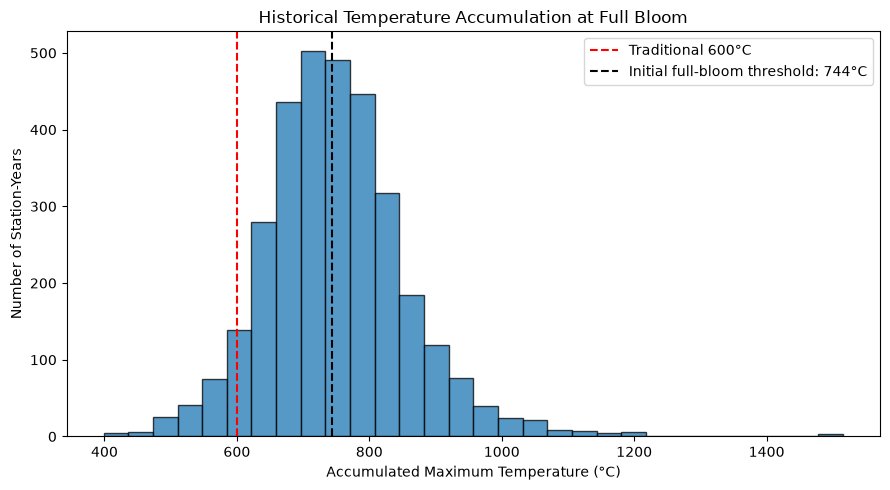

In [10]:
plt.figure(figsize=(9, 5))

plt.hist(
    calibration_df["accumulated_tmax"],
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    600,
    color="red",
    linestyle="--",
    label="Traditional 600°C"
)

plt.axvline(
    initial_threshold,
    color="black",
    linestyle="--",
    label=f"Initial full-bloom threshold: {initial_threshold:.0f}°C"
)

plt.xlabel("Accumulated Maximum Temperature (°C)")
plt.ylabel("Number of Station-Years")
plt.title("Historical Temperature Accumulation at Full Bloom")

plt.legend()
plt.tight_layout()
plt.show()

In [12]:
#historical temperature estimates
def prepare_daily_climatology(weather_df, train_end_year, lookback=30):

    history = weather_df[
        weather_df["year"].between(
            train_end_year - lookback + 1,
            train_end_year
        )
    ].dropna(subset=["maximum_temperature_c"])

    # Station-specific daily climatology
    station_clim = (
        history.groupby(["station_id", "month_day"])[
            "maximum_temperature_c"
        ].mean()
    )

    # National daily fallback
    national_clim = (
        history.groupby("month_day")[
            "maximum_temperature_c"
        ].mean()
    )

    return station_clim, national_clim


In [13]:
#Define the forecasting function
def predict_temperature_rule(
    station_id,
    year,
    issue_date,
    threshold,
    station_clim,
    national_clim,
    observed_lookup
):
    station_id = str(station_id)

    start = pd.Timestamp(year, 2, 1)
    end = pd.Timestamp(year, 6, 30)

    dates = pd.date_range(start, end, freq="D")

    cumulative = 0.0
    estimated_days = 0
    fallback_days = 0
    missing_observed_days = 0

    for date in dates:

        month_day = date.strftime("%m-%d")

        # February 29 fallback for sparse leap-day history
        if month_day == "02-29":
            fallback_day = "02-28"
        else:
            fallback_day = month_day

        key = (station_id, month_day)

        estimated = station_clim.get(key, np.nan)

        if pd.isna(estimated):
            estimated = station_clim.get(
                (station_id, fallback_day), np.nan
            )

        if pd.isna(estimated):
            estimated = national_clim.get(
                month_day, np.nan
            )
            fallback_days += 1

        if pd.isna(estimated):
            estimated = national_clim.get(
                fallback_day, np.nan
            )

        # Observed weather is permitted only BEFORE issue date
        if date < issue_date:
            actual = observed_lookup.get(
                (station_id, date), np.nan
            )

            if pd.notna(actual):
                temperature = actual
            else:
                temperature = estimated
                missing_observed_days += 1
                estimated_days += 1
        else:
            temperature = estimated
            estimated_days += 1

        if pd.isna(temperature):
            return {
                "predicted_doy": np.nan,
                "estimated_days": estimated_days,
                "fallback_days": fallback_days,
                "missing_observed_days": missing_observed_days,
                "status": "missing_temperature"
            }

        cumulative += temperature

        if cumulative >= threshold:
            return {
                "predicted_doy": date.dayofyear,
                "estimated_days": estimated_days,
                "fallback_days": fallback_days,
                "missing_observed_days": missing_observed_days,
                "status": "crossed"
            }

    return {
        "predicted_doy": np.nan,
        "estimated_days": estimated_days,
        "fallback_days": fallback_days,
        "missing_observed_days": missing_observed_days,
        "status": "threshold_not_reached"
    }


In [14]:
#Prepare the observed-temperature lookup
weather["station_id"] = weather["station_id"].astype(str)
weather["date"] = pd.to_datetime(weather["date"])

weather = weather.sort_values(["station_id", "date"])

assert not weather.duplicated(
    ["station_id", "date"]
).any(), "Duplicate station-date records detected"

observed_lookup = {
    (row.station_id, row.date): row.maximum_temperature_c
    for row in weather[
        ["station_id", "date", "maximum_temperature_c"]
    ].itertuples(index=False)
}

print("Daily weather lookup ready")


Daily weather lookup ready


In [15]:
#Run all five validation folds
all_predictions = []
threshold_records = []

for fold_no, train_df, val_df in cv_folds(feb_df):

    train_end_year = int(train_df["bloom_year"].max())

    print(f"Processing Fold {fold_no}...")

    # 1. Calibrate threshold using training observations
    calibration = calculate_full_bloom_accumulation(
        train_df, weather
    )

    threshold = calibration["accumulated_tmax"].median()

    threshold_records.append({
        "fold": fold_no,
        "train_end_year": train_end_year,
        "calibration_n": len(calibration),
        "threshold": threshold
    })

    # 2. Build historical temperature estimates
    station_clim, national_clim = prepare_daily_climatology(
        weather, train_end_year
    )

    # 3. Forecast both issue dates
    for issue in ["feb1", "mar1"]:

        for row in val_df.itertuples(index=False):

            year = int(row.bloom_year)

            issue_date = pd.Timestamp(
                year, 2 if issue == "feb1" else 3, 1
            )

            result = predict_temperature_rule(
                station_id=row.station_id,
                year=year,
                issue_date=issue_date,
                threshold=threshold,
                station_clim=station_clim,
                national_clim=national_clim,
                observed_lookup=observed_lookup
            )

            all_predictions.append({
                "fold": fold_no,
                "forecast_date": issue,
                "station_id": row.station_id,
                "year": year,
                "actual_doy": getattr(row, TARGET),
                "threshold": threshold,
                **result
            })

cv_predictions = pd.DataFrame(all_predictions)
threshold_results = pd.DataFrame(threshold_records)

print("\nCalibrated thresholds:")
display(threshold_results.round(2))

print("\nPrediction status:")
display(
    cv_predictions.groupby(
        ["forecast_date", "status"]
    ).size()
)


Processing Fold 1...
Processing Fold 2...
Processing Fold 3...
Processing Fold 4...
Processing Fold 5...

Calibrated thresholds:


,fold,train_end_year,calibration_n,threshold
0,1,2004,3262,744.20
1,2,2006,3410,744.55
2,3,2008,3537,746.30
3,4,2010,3643,747.40
4,5,2012,3741,748.20



Prediction status:


forecast_date  status 
feb1           crossed    575
mar1           crossed    575
dtype: int64

In [27]:

# Evaluate using the team's shared evaluation function

def evaluate_rule(data):
    valid = data.dropna(
        subset=["actual_doy", "predicted_doy"]
    )

    if len(valid) == 0:
        return {
            "n": 0,
            "MAE": np.nan,
            "RMSE": np.nan,
            "R2": np.nan,
            "hit_rate_3d": np.nan
        }

    return evaluate(
        valid["actual_doy"],
        valid["predicted_doy"]
    )


# Evaluate national temperature-rule predictions
fold_metrics = []

for (issue, fold), group in cv_predictions.groupby(
    ["forecast_date", "fold"]
):
    metrics = evaluate_rule(group)

    fold_metrics.append({
        "forecast_date": issue,
        "fold": fold,
        "total_n": len(group),
        **metrics
    })

fold_metrics = pd.DataFrame(fold_metrics)

display(fold_metrics.round(3))


,forecast_date,fold,total_n,n,MAE,RMSE,R2,hit_rate_3d
0,feb1,1,148,148,3.980,5.406,0.784,0.568
1,feb1,2,127,127,5.795,7.950,0.267,0.394
2,feb1,3,106,106,4.255,6.114,0.693,0.585
3,feb1,4,98,98,4.571,5.581,0.673,0.418
4,feb1,5,96,96,5.490,6.470,0.744,0.302
5,mar1,1,148,148,3.993,5.386,0.786,0.574
6,mar1,2,127,127,5.827,8.123,0.234,0.417
7,mar1,3,106,106,4.151,5.894,0.715,0.566
8,mar1,4,98,98,4.653,6.066,0.614,0.469
9,mar1,5,96,96,6.250,7.166,0.686,0.208


In [17]:
#Compare February and March performance
summary = (
    fold_metrics
    .groupby("forecast_date")[
        ["MAE", "RMSE", "R2", "hit_rate_3d"]
    ]
    .mean()
)

summary["hit_rate_3d"] *= 100

print("Adapted Temperature Rule — CV Summary")
display(summary.round(3))


Adapted Temperature Rule — CV Summary


,MAE,RMSE,R2,hit_rate_3d
forecast_date,,,,
feb1,4.818,6.304,0.632,45.332
mar1,4.975,6.527,0.607,44.708


In [18]:

cv_predictions["error"] = (
    cv_predictions["predicted_doy"]
    - cv_predictions["actual_doy"]
)

cv_predictions["absolute_error"] = (
    cv_predictions["error"].abs()
)

diagnostics = (
    cv_predictions
    .groupby("forecast_date")
    .agg(
        predictions=("predicted_doy", "count"),
        mean_error=("error", "mean"),
        median_error=("error", "median"),
        mean_absolute_error=("absolute_error", "mean"),
        estimated_days=("estimated_days", "mean"),
        fallback_days=("fallback_days", "sum"),
        missing_observed_days=("missing_observed_days", "sum")
    )
)

display(diagnostics.round(3))


,predictions,mean_error,median_error,mean_absolute_error,estimated_days,fallback_days,missing_observed_days
forecast_date,,,,,,,
feb1,575,1.310,2.0,4.784,69.470,0,0
mar1,575,0.503,1.0,4.917,40.475,0,0


In [19]:

march_predictions = cv_predictions[
    cv_predictions["forecast_date"] == "mar1"
].copy()

march_predictions["march1_doy"] = pd.to_datetime(
    march_predictions["year"].astype(str) + "-03-01"
).dt.dayofyear

march_predictions["predicted_before_issue"] = (
    march_predictions["predicted_doy"]
    < march_predictions["march1_doy"]
)

print(
    "Predictions before March 1:",
    march_predictions["predicted_before_issue"].sum()
)

display(
    march_predictions[
        march_predictions["predicted_before_issue"]
    ].head(10)
)


Predictions before March 1: 0


,fold,forecast_date,station_id,year,actual_doy,threshold,predicted_doy,estimated_days,fallback_days,missing_observed_days,status,error,absolute_error,march1_doy,predicted_before_issue


In [20]:
# Add region information to training calibration records
calibration_with_region = calibration_df.merge(
    train_df[["station_id", "bloom_year", "region"]],
    on=["station_id", "bloom_year"],
    how="left",
    validate="one_to_one"
)

regional_thresholds = (
    calibration_with_region
    .groupby("region")["accumulated_tmax"]
    .agg(["count", "median", "std"])
    .reset_index()
)

display(regional_thresholds.round(2))

,region,count,median,std
0,Chubu,697,715.2,70.52
1,Chugoku,327,746.7,52.58
2,Hokkaido,203,569.6,60.01
3,Kansai,489,761.9,74.50
4,Kanto,439,787.3,105.32
5,Kyushu,430,844.1,115.19
6,Shikoku,201,800.4,71.26
7,Tohoku,476,662.5,55.18


In [21]:
regional_predictions = []
regional_threshold_records = []

for fold_no, train_df, val_df in cv_folds(feb_df):

    train_end_year = int(train_df["bloom_year"].max())

    # Calculate temperature accumulation from training years only
    calibration = calculate_full_bloom_accumulation(
        train_df, weather
    )

    # Add region information
    calibration = calibration.merge(
        train_df[["station_id", "bloom_year", "region"]],
        on=["station_id", "bloom_year"],
        how="left",
        validate="one_to_one"
    )

    national_threshold = calibration[
        "accumulated_tmax"
    ].median()

    region_thresholds = (
        calibration.groupby("region")[
            "accumulated_tmax"
        ].median()
    )

    station_clim, national_clim = prepare_daily_climatology(
        weather, train_end_year
    )

    for region, threshold in region_thresholds.items():
        regional_threshold_records.append({
            "fold": fold_no,
            "region": region,
            "threshold": threshold
        })

    for issue in ["feb1", "mar1"]:

        for row in val_df.itertuples(index=False):

            year = int(row.bloom_year)

            issue_date = pd.Timestamp(
                year, 2 if issue == "feb1" else 3, 1
            )

            threshold = region_thresholds.get(
                row.region, national_threshold
            )

            result = predict_temperature_rule(
                station_id=row.station_id,
                year=year,
                issue_date=issue_date,
                threshold=threshold,
                station_clim=station_clim,
                national_clim=national_clim,
                observed_lookup=observed_lookup
            )

            regional_predictions.append({
                "fold": fold_no,
                "forecast_date": issue,
                "station_id": row.station_id,
                "year": year,
                "region": row.region,
                "actual_doy": getattr(row, TARGET),
                "threshold": threshold,
                **result
            })

regional_predictions = pd.DataFrame(regional_predictions)

print("Regional prediction status:")
display(
    regional_predictions.groupby(
        ["forecast_date", "status"]
    ).size()
)

Regional prediction status:


forecast_date  status 
feb1           crossed    575
mar1           crossed    575
dtype: int64

In [23]:
comparison = pd.DataFrame({
    "30yr_Climatology": {
        "MAE": 3.804,
        "RMSE": 4.573,
        "R2": 0.819,
        "hit_rate_3d": 0.457
    },
    "National_Feb1": summary.loc["feb1"],
    "Regional_Feb1": regional_summary.loc["feb1"],
    "National_Mar1": summary.loc["mar1"],
    "Regional_Mar1": regional_summary.loc["mar1"]
})

# National summary hit rates were previously multiplied by 100
comparison.loc["hit_rate_3d", [
    "National_Feb1",
    "National_Mar1"
]] /= 100

# Display all hit rates as percentages
comparison_display = comparison.copy()
comparison_display.loc["hit_rate_3d"] *= 100

display(comparison_display.round(3))

,30yr_Climatology,National_Feb1,Regional_Feb1,National_Mar1,Regional_Mar1
MAE,3.804,4.818,4.287,4.975,4.383
RMSE,4.573,6.304,5.406,6.527,5.532
R2,0.819,0.632,0.743,0.607,0.726
hit_rate_3d,45.700,45.332,48.477,44.708,48.229


In [28]:
regional_predictions.to_csv(
    OUTPUT / "temperature_regional_cv_predictions.csv",
    index=False
)

cv_predictions.to_csv(
    OUTPUT / "temperature_national_cv_predictions.csv",
    index=False
)

regional_fold_metrics.to_csv(
    OUTPUT / "temperature_regional_cv_metrics.csv",
    index=False
)

fold_metrics.to_csv(
    OUTPUT / "temperature_national_cv_metrics.csv",
    index=False
)

comparison.to_csv(
    OUTPUT / "baseline_validation_comparison.csv"
)

print("Baseline results saved successfully!")

Baseline results saved successfully!


In [29]:

from IPython.display import display, Markdown

summary = """
# Key Findings — Adapted 600°C Temperature Rule

## 1. Model Overview

The traditional 600°C rule estimates first flowering
using cumulative daily maximum temperatures from
February 1.

For Sakura Yosoku, the rule was adapted to predict
full-bloom day of year by recalibrating the
accumulated-temperature threshold using training data.

### Forecasting Strategy

**February 1:**
Future temperatures from February onward were
estimated using historical daily temperature averages.

**March 1:**
Observed February temperatures were combined with
historical daily estimates for March onward.

Both approaches respected the forecast-date cutoffs
in the forecasting function.

---

## 2. Temperature Threshold Calibration

The initial nationally calibrated threshold was:

**744.20°C**, calculated from 3,262 training
observations in the first validation fold.

Across the five folds, national thresholds ranged
from approximately 744.20°C to 748.20°C.

Regional threshold calibration revealed substantial
geographic differences.

| Region | Median Accumulated Tmax |
|---|---:|
| Hokkaido | 569.6°C |
| Tohoku | 662.5°C |
| Chubu | 715.2°C |
| Chugoku | 746.7°C |
| Kansai | 761.9°C |
| Kanto | 787.3°C |
| Shikoku | 800.4°C |
| Kyushu | 844.1°C |

*Regional values represent historical training
accumulations, not independent test results.*

---

## 3. Validation Performance

| Model | MAE | RMSE | R² | ±3-Day Hit Rate |
|---|---:|---:|---:|---:|
| National — Feb 1 | 4.818 | 6.304 | 0.632 | 45.33% |
| Regional — Feb 1 | **4.287** | **5.406** | **0.743** | **48.48%** |
| National — Mar 1 | 4.975 | 6.527 | 0.607 | 44.71% |
| Regional — Mar 1 | **4.383** | **5.532** | **0.726** | **48.23%** |

*Unweighted five-fold validation averages.*

---

## 4. Key Findings

### Finding 1 — Regional Calibration Improved Accuracy

Regional threshold calibration reduced MAE by:

- **11.0% for February 1**
- **11.9% for March 1**

The improvement indicates that geographic differences
in accumulated temperatures are relevant to bloom timing.

### Finding 2 — Hokkaido and Tohoku Benefited Most

Regional calibration reduced February 1 MAE by:

- Hokkaido: **4.629 days**
- Tohoku: **1.867 days**

However, regional calibration increased prediction
errors in Kanto and Shikoku for both forecast dates.

### Finding 3 — February 1 Slightly Outperformed March 1

The regional February 1 model achieved an MAE of
4.287 days, compared with 4.383 days for March 1.

Observed February temperatures did not automatically
improve overall forecast accuracy.

### Finding 4 — Forecast Coverage Was Complete

Both national and regional configurations generated
575 validation predictions for each forecast date.

All threshold crossings occurred within the
supported forecast horizon.

No regional model predictions occurred before
their respective forecast issue dates.

---

## 5. Model Limitations

- Future temperatures are estimated from historical
  daily averages rather than seasonal weather forecasts.
- A single national threshold cannot adequately
  represent every Japanese climatic region.
- Regional thresholds still overlook local
  microclimatic and station-specific differences.
- The median accumulated-temperature threshold is
  a training-derived calibration method, not an
  MAE-optimized threshold.
- Leap-day handling and upstream weather-imputation
  cutoff safety require final verification.
- Model configuration selection was based on
  validation performance; final test performance
  remains unknown.

---

## 6. Conclusion

**The regionally calibrated temperature rule was
selected as the preferred temperature-based baseline.**

It outperformed the national temperature threshold
for both February 1 and March 1 forecasts.

However, it did not outperform the 30-year
Station Climatology in validation MAE.

The national temperature rule was retained as
a reference benchmark, while the regional
configuration was selected for final comparison
against the team's advanced models.

**The 2015–2025 test period remains untouched.**
"""

display(Markdown(summary))



# Key Findings — Adapted 600°C Temperature Rule

## 1. Model Overview

The traditional 600°C rule estimates first flowering
using cumulative daily maximum temperatures from
February 1.

For Sakura Yosoku, the rule was adapted to predict
full-bloom day of year by recalibrating the
accumulated-temperature threshold using training data.

### Forecasting Strategy

**February 1:**
Future temperatures from February onward were
estimated using historical daily temperature averages.

**March 1:**
Observed February temperatures were combined with
historical daily estimates for March onward.

Both approaches respected the forecast-date cutoffs
in the forecasting function.

---

## 2. Temperature Threshold Calibration

The initial nationally calibrated threshold was:

**744.20°C**, calculated from 3,262 training
observations in the first validation fold.

Across the five folds, national thresholds ranged
from approximately 744.20°C to 748.20°C.

Regional threshold calibration revealed substantial
geographic differences.

| Region | Median Accumulated Tmax |
|---|---:|
| Hokkaido | 569.6°C |
| Tohoku | 662.5°C |
| Chubu | 715.2°C |
| Chugoku | 746.7°C |
| Kansai | 761.9°C |
| Kanto | 787.3°C |
| Shikoku | 800.4°C |
| Kyushu | 844.1°C |

*Regional values represent historical training
accumulations, not independent test results.*

---

## 3. Validation Performance

| Model | MAE | RMSE | R² | ±3-Day Hit Rate |
|---|---:|---:|---:|---:|
| National — Feb 1 | 4.818 | 6.304 | 0.632 | 45.33% |
| Regional — Feb 1 | **4.287** | **5.406** | **0.743** | **48.48%** |
| National — Mar 1 | 4.975 | 6.527 | 0.607 | 44.71% |
| Regional — Mar 1 | **4.383** | **5.532** | **0.726** | **48.23%** |

*Unweighted five-fold validation averages.*

---

## 4. Key Findings

### Finding 1 — Regional Calibration Improved Accuracy

Regional threshold calibration reduced MAE by:

- **11.0% for February 1**
- **11.9% for March 1**

The improvement indicates that geographic differences
in accumulated temperatures are relevant to bloom timing.

### Finding 2 — Hokkaido and Tohoku Benefited Most

Regional calibration reduced February 1 MAE by:

- Hokkaido: **4.629 days**
- Tohoku: **1.867 days**

However, regional calibration increased prediction
errors in Kanto and Shikoku for both forecast dates.

### Finding 3 — February 1 Slightly Outperformed March 1

The regional February 1 model achieved an MAE of
4.287 days, compared with 4.383 days for March 1.

Observed February temperatures did not automatically
improve overall forecast accuracy.

### Finding 4 — Forecast Coverage Was Complete

Both national and regional configurations generated
575 validation predictions for each forecast date.

All threshold crossings occurred within the
supported forecast horizon.

No regional model predictions occurred before
their respective forecast issue dates.

---

## 5. Model Limitations

- Future temperatures are estimated from historical
  daily averages rather than seasonal weather forecasts.
- A single national threshold cannot adequately
  represent every Japanese climatic region.
- Regional thresholds still overlook local
  microclimatic and station-specific differences.
- The median accumulated-temperature threshold is
  a training-derived calibration method, not an
  MAE-optimized threshold.
- Leap-day handling and upstream weather-imputation
  cutoff safety require final verification.
- Model configuration selection was based on
  validation performance; final test performance
  remains unknown.

---

## 6. Conclusion

**The regionally calibrated temperature rule was
selected as the preferred temperature-based baseline.**

It outperformed the national temperature threshold
for both February 1 and March 1 forecasts.

However, it did not outperform the 30-year
Station Climatology in validation MAE.

The national temperature rule was retained as
a reference benchmark, while the regional
configuration was selected for final comparison
against the team's advanced models.

**The 2015–2025 test period remains untouched.**
